
# Synthetic attribution experiment

> Насколько `first / last / linear / position` правильно ранжируют рекламные размещения по эффективности, если основной объём продаж создаёт естественный/сезонный спрос, а реклама даёт меньший incremental lift?

Ключевая идея генератора:

1. Исторические данные `base.csv / base.xlsx` используются для калибровки:
   - распределения чеков;
   - структуры заказов и пакетов;
   - доли повторных покупателей;
   - временного профиля спроса.
2. Сначала возникает **organic demand**.
3. Только если органическая покупка не произошла, реклама может создать **дополнительную** покупку.
4. Истинный драйвер рекламной покупки (`true_driver`) сохраняется только в hidden ground truth и **не передаётся attribution engine**.
5. Рекламные размещения специально ставятся рядом с периодами высокого спроса. Это создаёт реалистичную ловушку: attribution может приписать рекламе продажи, которые случились бы и без неё.

Для расчёта аттрибуции используются правила из `src/core/attribution.py`.  
Вне репозитория включается компактный fallback с теми же четырьмя правилами распределения выручки между касаниями.



## 0. Запуск

Эта версия ноутбука умеет запускаться прямо из GitHub через Colab.

Если ноутбук открыт в Colab:

1. репозиторий автоматически клонируется в `/content/hackaton_project`;
2. устанавливаются зависимости из `requirements.txt`, если файл существует;
3. рабочая директория переключается на корень репозитория;
4. `src/` добавляется в `sys.path`;
5. исторические данные читаются из репозитория;
6. расчёт attribution выполняется через текущий `src/core/attribution.py`.

Если ноутбук запускается локально внутри репозитория, повторное клонирование не выполняется.


In [26]:

# --- Colab / local bootstrap ---
from pathlib import Path
import os
import sys
import subprocess

REPO_URL = "https://github.com/valentinesvev/hackaton_project.git"
REPO_DIR = Path("/content/hackaton_project")

IN_COLAB = "google.colab" in sys.modules or Path("/content").exists()

if IN_COLAB:
    if not REPO_DIR.exists():
        print("Cloning repository...")
        subprocess.run(["git", "clone", REPO_URL, str(REPO_DIR)], check=True)
    else:
        print("Repository already exists:", REPO_DIR)

    os.chdir(REPO_DIR)

    requirements = REPO_DIR / "requirements.txt"
    if requirements.exists():
        print("Installing requirements...")
        subprocess.run(
            [sys.executable, "-m", "pip", "install", "-q", "-r", str(requirements)],
            check=True
        )
    else:
        print("requirements.txt not found — using current environment.")

    ROOT = REPO_DIR
else:
    # Локальный запуск: определяем корень репозитория.
    ROOT = Path.cwd()
    if ROOT.name == "notebooks":
        ROOT = ROOT.parent

src_dir = ROOT / "src"
if str(src_dir) not in sys.path:
    sys.path.insert(0, str(src_dir))

print("Working directory:", Path.cwd())
print("Project root:", ROOT)
print("src in sys.path:", src_dir)


Repository already exists: /content/hackaton_project
Installing requirements...
Working directory: /content/hackaton_project
Project root: /content/hackaton_project
src in sys.path: /content/hackaton_project/src


In [27]:

from pathlib import Path
import sys
import math
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 42
N_USERS = 1000
N_RUNS = 30
WINDOW_DAYS = 30
ACQUIRING_RATE = 0.03
DECAY_DAYS = 7.0

# ROOT is set by the Colab/local bootstrap cell above.

OUTPUT_DIR = ROOT / "outputs" / "charts"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Если ноутбук лежит в репозитории — используем production attribution.py.
USE_PRODUCTION_ENGINE = False
try:
    from core.db import connect
    from core import attribution
    USE_PRODUCTION_ENGINE = True
    print("Engine: production src/core/attribution.py")
except Exception as exc:
    print("Engine: notebook fallback (production module не найден в текущем окружении)")
    print("Reason:", type(exc).__name__, str(exc)[:200])


Engine: production src/core/attribution.py



## 1. Калибровка по историческим продажам

Сначала собираем **заказы**, а не считаем каждую строку исходного файла отдельной покупкой.

Правило нормализации для базового эксперимента:

- строки одного `student_id` с **одинаковым timestamp** считаем одним заказом;
- сумма заказа = сумма строк;
- несколько курсов внутри такого заказа считаем bundle;
- повторный покупатель = пользователь с более чем одним distinct order.

Это приближение явно фиксируем как assumption.


In [28]:

def find_history_file(root: Path):
    candidates = [
        root / "data" / "raw" / "base.csv",
        root / "data" / "raw" / "base.xlsx",
        root / "data" / "base.csv",
        root / "data" / "base.xlsx",
        root / "base.csv",
        root / "base.xlsx",
        Path("/mnt/data/base.csv"),
        Path("/mnt/data/base.xlsx"),
    ]
    for p in candidates:
        if p.exists():
            return p
    return None


def load_history(root=ROOT):
    path = find_history_file(root)

    if path is None:
        # Удобно при запуске ноутбука прямо из GitHub/Colab.
        url = "https://raw.githubusercontent.com/valentinesvev/hackaton_project/main/data/raw/base.csv"
        try:
            raw = pd.read_csv(url)
            source = url
        except Exception:
            return None, None
    else:
        source = str(path)
        raw = pd.read_excel(path) if path.suffix.lower() == ".xlsx" else pd.read_csv(path)

    # Поддерживаем русские имена из исходного base и английские варианты.
    rename_map = {
        "Номер студента": "student_id",
        "Сумма": "amount",
        "Курс": "course",
        "Время": "timestamp",
    }
    raw = raw.rename(columns=rename_map).copy()

    if "amount" in raw:
        raw["amount"] = (
            raw["amount"].astype(str)
            .str.replace(r"\s", "", regex=True)
            .str.replace(",", ".", regex=False)
            .astype(float)
        )

    raw["timestamp"] = pd.to_datetime(raw["timestamp"], dayfirst=True, errors="coerce")
    raw = raw.dropna(subset=["student_id", "amount", "timestamp"]).copy()

    # Одновременные строки одного пользователя -> один order/bundle.
    orders = (
        raw.groupby(["student_id", "timestamp"], as_index=False)
        .agg(
            amount=("amount", "sum"),
            n_items=("course", "size"),
            courses=("course", lambda x: tuple(x.astype(str))),
        )
        .sort_values("timestamp")
        .reset_index(drop=True)
    )
    orders["order_id"] = np.arange(1, len(orders) + 1)

    return raw, orders


history_raw, history_orders = load_history()

if history_orders is not None:
    repeat_rate = (
        history_orders.groupby("student_id").size().gt(1).mean()
    )
    bundle_rate = history_orders["n_items"].gt(1).mean()

    daily = (
        history_orders.assign(day=history_orders["timestamp"].dt.normalize())
        .groupby("day").size()
        .rename("orders")
        .asfreq("D", fill_value=0)
    )
    # Сглаживаем случайный дневной шум, но сохраняем форму пиков.
    demand_profile = daily.rolling(5, center=True, min_periods=1).mean()
    demand_index = demand_profile / demand_profile.mean()

    amount_pool = history_orders["amount"].to_numpy(float)

    print("History source:", find_history_file(ROOT) or "GitHub raw/base.csv")
    print("Normalized orders:", len(history_orders))
    print("Unique buyers:", history_orders["student_id"].nunique())
    print("Bundle share:", round(bundle_rate, 3))
    print("Repeat-buyer share:", round(repeat_rate, 3))
    print("Median order:", round(float(np.median(amount_pool)), 0), "₽")
else:
    # Fallback только для preview, если исторический файл недоступен.
    repeat_rate = 0.20
    bundle_rate = 0.18
    amount_pool = np.array([4950, 6490, 6950, 8245, 8745, 8950, 9950, 14950, 16950], dtype=float)

    idx = pd.date_range("2026-08-04", "2026-09-10", freq="D")
    x = np.arange(len(idx))
    profile = (
        0.65
        + 1.8 * np.exp(-0.5 * ((x - 5) / 2.8) ** 2)
        + 1.1 * np.exp(-0.5 * ((x - 31) / 3.2) ** 2)
    )
    demand_index = pd.Series(profile / profile.mean(), index=idx, name="demand_index")

    print("Исторический файл недоступен: используется fallback-калибровка только для preview.")


History source: /content/hackaton_project/data/raw/base.csv
Normalized orders: 628
Unique buyers: 606
Bundle share: 0.244
Repeat-buyer share: 0.033
Median order: 8950.0 ₽


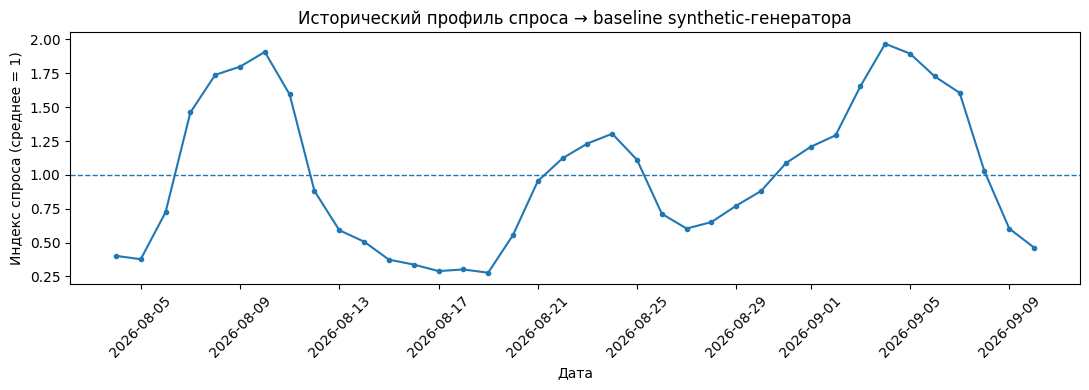

saved: /content/hackaton_project/outputs/charts/synthetic_demand_profile.png


In [29]:

# Визуализация профиля спроса, который используется генератором.
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(demand_index.index, demand_index.values, marker="o", markersize=3)
ax.axhline(1.0, linestyle="--", linewidth=1)
ax.set_title("Исторический профиль спроса → baseline synthetic-генератора")
ax.set_ylabel("Индекс спроса (среднее = 1)")
ax.set_xlabel("Дата")
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()

DEMAND_CHART = OUTPUT_DIR / "synthetic_demand_profile.png"
fig.savefig(DEMAND_CHART, dpi=160, bbox_inches="tight")
plt.show()
print("saved:", DEMAND_CHART)



## 2. Рекламные размещения и скрытый causal ground truth

У каждого placement есть:

- `publication_time` и `cost`, которые видит рабочая система;
- `reach` и `true_daily_lift`, которые существуют **только внутри генератора**.

`true_daily_lift` — небольшая дополнительная вероятность покупки после рекламного касания.  
Она экспоненциально затухает по времени.

Важно: размещения стоят рядом с периодами высокого естественного спроса. Поэтому даже слабая реклама может оказаться “последним касанием” перед большим органическим всплеском.


### Настройки параметров генерации (Конфигурация)

Ниже представлены ключевые параметры, управляющие поведением симулятора:
* `BASE_DAILY_ORGANIC_PROB` (по умолчанию `0.018`): Базовая вероятность того, что пользователь совершит органическую покупку в течение дня. Повышение этого параметра увеличивает долю органических продаж, усложняя задачу для атрибуции (увеличивается «шум»).
* `DECAY_DAYS` (по умолчанию `7.0`): Время полураспада рекламного эффекта. Чем больше значение, тем дольше реклама продолжает оказывать влияние на пользователя.
* `ACQUIRING_RATE` (по умолчанию `0.03`): Комиссия за эквайринг (влияет на расчет чистой маржи).
* `PROPENSITY_SIGMA` (по умолчанию `0.45`): Разброс индивидуальной склонности к покупке у пользователей. Большие значения создают выраженные сегменты «горячих» покупателей.

In [30]:
# ==========================================
# ГЛОБАЛЬНЫЕ НАСТРОЙКИ СИМУЛЯТОРА (КОНФИГУРАЦИЯ)
# ==========================================

# Базовая дневная вероятность органической покупки для среднего пользователя
BASE_DAILY_ORGANIC_PROB = 0.015

# Разброс индивидуальной склонности к покупке у пользователей (Log-Normal распределение)
PROPENSITY_SIGMA = 0.45
PROPENSITY_MIN = 0.40
PROPENSITY_MAX = 2.50

# Ограничение окна атрибуции (дней)
WINDOW_DAYS = 30

# Комиссия за эквайринг (влияет на чистую маржу)
ACQUIRING_RATE = 0.03

# Сила синергетического эффекта при совпадении рекламы анонса и вебинара (мультипликатор)
EVENT_SYNERGY_MULTIPLIER = 1.6

# Базовый период затухания по умолчанию (дней)
DEFAULT_DECAY_DAYS = 7.0


In [31]:
# Определение календаря событий компании (вебинары, старты курсов)
company_events = pd.DataFrame([
    {
        "event_name": "free_webinar_launch",
        "event_type": "webinar",
        "event_date": SIM_START + pd.Timedelta(days=25),
        "organic_lift_factor": 1.8  # Во сколько раз увеличивается органический спрос в день события
    },
    {
        "event_name": "course_start_promo",
        "event_type": "promo_start",
        "event_date": SIM_START + pd.Timedelta(days=8),
        "organic_lift_factor": 1.4
    }
])

# Новая детальная конфигурация размещений с учетом категорий постов и просмотров
placements = pd.DataFrame([
    {
        "placement_id": "a", "channel": "tg_ml_jobs", "campaign_name": "autumn_2026",
        "placement_type": "external", "creative": "creative_a",
        "post_category": "sale_discount", # Быстро затухает, дает высокий пик
        "discount_value": 10, "cost": 70000,
        "publication_time": SIM_START + pd.Timedelta(days=3),
        "reach": 15000, "views_count": 12000, "true_daily_lift": 0.0070,
    },
    {
        "placement_id": "b", "channel": "tg_data_jobs", "campaign_name": "autumn_2026",
        "placement_type": "external", "creative": "creative_b",
        "post_category": "regular_post", # Среднее затухание
        "discount_value": 0, "cost": 55000,
        "publication_time": SIM_START + pd.Timedelta(days=13),
        "reach": 12000, "views_count": 8500, "true_daily_lift": 0.0045,
    },
    {
        "placement_id": "c", "channel": "tg_students", "campaign_name": "autumn_2026",
        "placement_type": "external", "creative": "creative_c",
        "post_category": "event_announcement", # Греет перед вебинаром, синергирует с событиями
        "discount_value": 0, "cost": 40000,
        "publication_time": SIM_START + pd.Timedelta(days=23), # Опубликовано ровно перед вебинаром
        "reach": 10000, "views_count": 7200, "true_daily_lift": 0.0055,
    },
    {
        "placement_id": "d", "channel": "tg_career", "campaign_name": "autumn_2026",
        "placement_type": "external", "creative": "creative_d",
        "post_category": "expert_content", # Долгосрочный эффект прогрева
        "discount_value": 0, "cost": 40000,
        "publication_time": SIM_START + pd.Timedelta(days=30),
        "reach": 20000, "views_count": 16000, "true_daily_lift": 0.0018,
    },
])

PLACEMENT_LOOKUP = placements.set_index("placement_id").to_dict("index")
display(placements)


,placement_id,channel,campaign_name,placement_type,creative,post_category,discount_value,cost,publication_time,reach,views_count,true_daily_lift
0,a,tg_ml_jobs,autumn_2026,external,creative_a,sale_discount,10,70000,2026-08-07,15000,12000,0.0070
1,b,tg_data_jobs,autumn_2026,external,creative_b,regular_post,0,55000,2026-08-17,12000,8500,0.0045
2,c,tg_students,autumn_2026,external,creative_c,event_announcement,0,40000,2026-08-27,10000,7200,0.0055
3,d,tg_career,autumn_2026,external,creative_d,expert_content,0,40000,2026-09-03,20000,16000,0.0018


In [32]:
def get_dynamic_decay(category):
    # Возвращает индивидуальное время полураспада в зависимости от типа поста
    if category == "sale_discount":
        return 3.0  # Эффект скидки быстро исчезает
    elif category == "event_announcement":
        return 5.0  # Фокус на событие
    elif category == "expert_content":
        return 14.0  # Полезный контент греет очень долго
    else:
        return DEFAULT_DECAY_DAYS

def get_event_multiplier(day):
    # Проверяем, есть ли в этот день запланированные вебинары/промо
    target_day = pd.Timestamp(day).normalize()
    matches = company_events[company_events["event_date"].dt.normalize() == target_day]
    if not matches.empty:
        return float(matches["organic_lift_factor"].iloc[0])
    return 1.0

def decayed_effect_v2(pid, age_days, is_event_day=False):
    if age_days < 0 or age_days > WINDOW_DAYS:
        return 0.0
    meta = PLACEMENT_LOOKUP[pid]
    decay = get_dynamic_decay(meta["post_category"])

    # Базовое затухание
    base_lift = float(meta["true_daily_lift"]) * math.exp(-age_days / decay)

    # Если это день вебинара и реклама была анонсом этого мероприятия — даем мощную синергию
    if is_event_day and meta["post_category"] == "event_announcement":
        base_lift *= EVENT_SYNERGY_MULTIPLIER

    return base_lift


In [33]:
def generate_synthetic_v2(seed=SEED, n_users=N_USERS):
    rng = np.random.default_rng(seed)
    days = pd.date_range(SIM_START, SIM_END, freq="D")

    users, touches, events, leads, orders, order_items = [], [], [], [], [], []
    order_truth, user_truth = [], []

    touch_id = 1
    event_id = 1
    lead_id = 1
    item_id = 1

    for i in range(n_users):
        uid = f"u{i:05d}"
        propensity = float(rng.lognormal(mean=-0.08, sigma=PROPENSITY_SIGMA))
        propensity = float(np.clip(propensity, PROPENSITY_MIN, PROPENSITY_MAX))
        user_touches = []

        def add_touch(ts, pid):
            nonlocal touch_id
            row = {
                "touch_id": touch_id,
                "user_id_hash": uid,
                "placement_id": pid,
                "touch_type": "bot_start",
                "timestamp": pd.Timestamp(ts),
                "is_synthetic": 1,
            }
            touches.append(row)
            user_touches.append(row)
            touch_id += 1
            return row

        # Охват на основе реальных просмотров постов (виральность)
        for p in placements.itertuples():
            # Переводим абсолютные просмотры в вероятности соприкосновения
            empirical_reach = (p.views_count / 50000.0)
            click_prob = min(0.90, empirical_reach * (0.8 + 0.2 * propensity))
            if rng.random() < click_prob:
                lag_hours = int(rng.integers(0, 48))
                add_touch(pd.Timestamp(p.publication_time) + pd.Timedelta(hours=lag_hours), p.placement_id)

        # Органический приход в воронку
        if rng.random() < ORGANIC_BOT_START_PROB:
            organic_ts = SIM_START + pd.Timedelta(
                days=int(rng.integers(0, max(1, (SIM_END - SIM_START).days + 1))),
                hours=int(rng.integers(8, 22)),
            )
            add_touch(organic_ts, None)

        if not user_touches:
            first_seen = SIM_START + pd.Timedelta(days=int(rng.integers(0, 5)))
            first_pid = None
        else:
            user_touches.sort(key=lambda r: r["timestamp"])
            first_seen = user_touches[0]["timestamp"]
            first_pid = user_touches[0]["placement_id"]

        users.append({
            "user_id_hash": uid,
            "username_hash": None,
            "first_seen": first_seen,
            "first_placement_id": first_pid,
            "source_system": "bot",
        })

        prev_order_ts = None
        order_no = 0

        for day in days:
            if order_no >= 2:
                break

            repeat_multiplier = 1.0 if order_no == 0 else min(0.55, max(0.20, repeat_rate * 1.8))

            # Учитываем внешние события и вебинары для базовой вероятности
            event_lift = get_event_multiplier(day)
            p_org = BASE_DAILY_ORGANIC_PROB * demand_at(day) * propensity * repeat_multiplier * event_lift
            p_org = min(p_org, 0.25)

            purchase_kind = None
            true_driver = None

            if rng.random() < p_org:
                purchase_kind = "organic"
            else:
                eligible = eligible_paid_touches(user_touches, day + pd.Timedelta(hours=18), prev_order_ts)
                effects = []
                is_event_day = (event_lift > 1.0)

                for t, age in eligible:
                    eff = decayed_effect_v2(t["placement_id"], age, is_event_day=is_event_day)
                    if eff > 0:
                        effects.append((t["placement_id"], eff))

                total_ad_p = min(0.15, sum(e for _, e in effects))
                if effects and rng.random() < total_ad_p:
                    purchase_kind = "ad_incremental"
                    pids = [pid for pid, _ in effects]
                    weights = np.array([e for _, e in effects], dtype=float)
                    weights /= weights.sum()
                    true_driver = rng.choice(pids, p=weights)

            if purchase_kind is None:
                continue

            purchase_ts = pd.Timestamp(day) + pd.Timedelta(
                hours=int(rng.integers(10, 22)),
                minutes=int(rng.integers(0, 60)),
            )
            if prev_order_ts is not None and purchase_ts <= prev_order_ts + pd.Timedelta(days=3):
                continue

            order_no += 1
            amount = sample_amount(rng)
            order_id = f"o_{uid}_{order_no}"

            orders.append({
                "order_id": order_id,
                "user_id_hash": uid,
                "lead_id": lead_id,
                "student_id": None,
                "amount": amount,
                "variable_costs": round(amount * ACQUIRING_RATE, 2),
                "variable_costs_source": "rate_estimate",
                "timestamp": purchase_ts,
                "source_system": "bot",
                "is_synthetic": 1,
            })

            order_truth.append({
                "order_id": order_id,
                "user_id_hash": uid,
                "timestamp": purchase_ts,
                "amount": amount,
                "purchase_kind": purchase_kind,
                "true_driver": true_driver,
                "demand_index": demand_at(day) * event_lift,
            })
            lead_id += 1

    return {
        "dim_placement": placements.copy(),
        "dim_user": pd.DataFrame(users),
        "fact_touch": pd.DataFrame(touches),
        "fact_order": pd.DataFrame(orders),
        "order_truth": pd.DataFrame(order_truth),
    }

# Генерируем новый обновленный набор данных
frames = generate_synthetic_v2()
print(f"Успешно сгенерирована новая симуляция! Заказов: {len(frames['fact_order'])}.")


Успешно сгенерирована новая симуляция! Заказов: 525.


In [34]:
# Глобальные настройки генератора для экспериментов
BASE_DAILY_ORGANIC_PROB = 0.018
PROPENSITY_MIN = 0.45
PROPENSITY_MAX = 2.4
PROPENSITY_SIGMA = 0.45
ORGANIC_BOT_START_PROB = 0.28


In [35]:

SIM_START = pd.Timestamp(demand_index.index.min())
SIM_END = pd.Timestamp(demand_index.index.max())

# D специально публикуется около позднего пика: большой reach, но слабый true lift.
# Это стресс-тест для last touch.
placements = pd.DataFrame([
    {
        "placement_id": "a", "channel": "tg_ml_jobs", "campaign_name": "autumn_2026",
        "placement_type": "external", "creative": "creative_a", "post_category": "sale",
        "discount_value": 0, "cost": 70000,
        "publication_time": SIM_START + pd.Timedelta(days=3),
        "reach": 0.24, "true_daily_lift": 0.0060,
    },
    {
        "placement_id": "b", "channel": "tg_data_jobs", "campaign_name": "autumn_2026",
        "placement_type": "external", "creative": "creative_b", "post_category": "native",
        "discount_value": 0, "cost": 55000,
        "publication_time": SIM_START + pd.Timedelta(days=13),
        "reach": 0.22, "true_daily_lift": 0.0048,
    },
    {
        "placement_id": "c", "channel": "tg_students", "campaign_name": "autumn_2026",
        "placement_type": "external", "creative": "creative_c", "post_category": "discount",
        "discount_value": 15, "cost": 40000,
        "publication_time": SIM_START + pd.Timedelta(days=23),
        "reach": 0.18, "true_daily_lift": 0.0035,
    },
    {
        "placement_id": "d", "channel": "tg_career", "campaign_name": "autumn_2026",
        "placement_type": "external", "creative": "creative_d", "post_category": "content",
        "discount_value": 0, "cost": 40000,
        "publication_time": SIM_START + pd.Timedelta(days=30),
        "reach": 0.34, "true_daily_lift": 0.0015,
    },
])

display(
    placements[
        ["placement_id", "channel", "publication_time", "cost", "reach", "true_daily_lift"]
    ]
)


PLACEMENT_LOOKUP = placements.set_index("placement_id").to_dict("index")


,placement_id,channel,publication_time,cost,reach,true_daily_lift
0,a,tg_ml_jobs,2026-08-07,70000,0.24,0.0060
1,b,tg_data_jobs,2026-08-17,55000,0.22,0.0048
2,c,tg_students,2026-08-27,40000,0.18,0.0035
3,d,tg_career,2026-09-03,40000,0.34,0.0015



## 3. Генератор

### Покупка возникает в два этапа

Для каждого user-day:

1. С вероятностью `p_organic` происходит **органическая** покупка.
   - `p_organic` зависит от исторического demand index;
   - у пользователей есть латентная склонность к покупке.
2. Только если органическая покупка не произошла, реклама может дать дополнительную покупку.
   - учитываются только рекламные touches после предыдущей покупки;
   - эффект касания затухает;
   - если рекламная покупка произошла, `true_driver` выбирается пропорционально скрытому эффекту placement.

Так мы точно знаем, какая продажа **добавлена рекламой**, а какая произошла бы и без неё.

Это специально отличается от rule-based attribution: production engine не знает `true_driver`.


In [36]:

def demand_at(day):
    day = pd.Timestamp(day).normalize()
    if day in demand_index.index:
        return float(demand_index.loc[day])

    # На случай несовпадения индексов — ближайший день.
    pos = demand_index.index.get_indexer([day], method="nearest")[0]
    return float(demand_index.iloc[pos])


def decayed_effect(pid, age_days):
    if age_days < 0 or age_days > WINDOW_DAYS:
        return 0.0
    return float(PLACEMENT_LOOKUP[pid]["true_daily_lift"]) * math.exp(-age_days / DECAY_DAYS)


def sample_amount(rng):
    return float(rng.choice(amount_pool))


def eligible_paid_touches(user_touches, day, prev_order_ts=None):
    out = []
    day = pd.Timestamp(day)

    for t in user_touches:
        pid = t["placement_id"]
        if pid is None:
            continue

        ts = pd.Timestamp(t["timestamp"])
        age = (day - ts).total_seconds() / 86400

        if 0 <= age <= WINDOW_DAYS:
            if prev_order_ts is None or ts > pd.Timestamp(prev_order_ts):
                out.append((t, age))

    return out


def generate_synthetic(seed=SEED, n_users=N_USERS):
    rng = np.random.default_rng(seed)
    days = pd.date_range(SIM_START, SIM_END, freq="D")

    users, touches, events, leads, orders, order_items = [], [], [], [], [], []
    order_truth, user_truth = [], []

    touch_id = 1
    event_id = 1
    lead_id = 1
    item_id = 1

    # Калибруем среднюю дневную organic probability так,
    # чтобы за весь период значимая доля пользователей могла купить.
    base_daily_purchase = 0.018

    for i in range(n_users):
        uid = f"u{i:05d}"

        # Латентная склонность: часть пользователей заметно "горячее" остальных.
        propensity = float(rng.lognormal(mean=-0.08, sigma=0.45))
        propensity = float(np.clip(propensity, 0.45, 2.4))

        user_touches = []

        def add_touch(ts, pid):
            nonlocal touch_id
            row = {
                "touch_id": touch_id,
                "user_id_hash": uid,
                "placement_id": pid,
                "touch_type": "bot_start",
                "timestamp": pd.Timestamp(ts),
                "is_synthetic": 1,
            }
            touches.append(row)
            user_touches.append(row)
            touch_id += 1
            return row

        # Mild selection: более "горячие" пользователи чуть чаще кликают рекламу.
        for p in placements.itertuples():
            click_prob = min(0.90, p.reach * (0.8 + 0.2 * propensity))
            if rng.random() < click_prob:
                lag_hours = int(rng.integers(0, 60))
                add_touch(pd.Timestamp(p.publication_time) + pd.Timedelta(hours=lag_hours), p.placement_id)

        # Часть пользователей приходит в бот органически.
        if rng.random() < 0.28:
            organic_ts = SIM_START + pd.Timedelta(
                days=int(rng.integers(0, max(1, (SIM_END - SIM_START).days + 1))),
                hours=int(rng.integers(8, 22)),
            )
            add_touch(organic_ts, None)

        if not user_touches:
            # Пользователь всё равно существует в dim_user, даже если в бот не заходил.
            first_seen = SIM_START + pd.Timedelta(days=int(rng.integers(0, 5)))
            first_pid = None
        else:
            user_touches.sort(key=lambda r: r["timestamp"])
            first_seen = user_touches[0]["timestamp"]
            first_pid = user_touches[0]["placement_id"]

        users.append({
            "user_id_hash": uid,
            "username_hash": None,
            "first_seen": first_seen,
            "first_placement_id": first_pid,
            "source_system": "bot",
        })

        user_truth.append({
            "user_id_hash": uid,
            "propensity": propensity,
            "n_ad_touches": sum(t["placement_id"] is not None for t in user_touches),
        })

        prev_order_ts = None
        order_no = 0

        # Ограничиваемся максимум двумя заказами на пользователя.
        for day in days:
            if order_no >= 2:
                break

            # После первой покупки вероятность второй покупки ниже.
            repeat_multiplier = 1.0 if order_no == 0 else min(0.55, max(0.20, repeat_rate * 1.8))

            p_org = base_daily_purchase * demand_at(day) * propensity * repeat_multiplier
            p_org = min(p_org, 0.20)

            purchase_kind = None
            true_driver = None

            # 1) Natural/seasonal demand.
            if rng.random() < p_org:
                purchase_kind = "organic"

            else:
                # 2) Small incremental ad lift.
                eligible = eligible_paid_touches(user_touches, day + pd.Timedelta(hours=18), prev_order_ts)

                effects = []
                for t, age in eligible:
                    eff = decayed_effect(t["placement_id"], age)
                    if eff > 0:
                        effects.append((t["placement_id"], eff))

                total_ad_p = min(0.12, sum(e for _, e in effects))

                if effects and rng.random() < total_ad_p:
                    purchase_kind = "ad_incremental"

                    pids = [pid for pid, _ in effects]
                    weights = np.array([e for _, e in effects], dtype=float)
                    weights /= weights.sum()
                    true_driver = rng.choice(pids, p=weights)

            if purchase_kind is None:
                continue

            # Не создаём вторую покупку слишком быстро.
            purchase_ts = pd.Timestamp(day) + pd.Timedelta(
                hours=int(rng.integers(10, 22)),
                minutes=int(rng.integers(0, 60)),
            )
            if prev_order_ts is not None and purchase_ts <= prev_order_ts + pd.Timedelta(days=3):
                continue

            order_no += 1
            amount = sample_amount(rng)

            # Привязываем lead к последнему известному touch до покупки.
            before = [t for t in user_touches if t["timestamp"] <= purchase_ts]
            lead_touch_id = max(before, key=lambda x: x["timestamp"])["touch_id"] if before else None

            leads.append({
                "lead_id": lead_id,
                "user_id_hash": uid,
                "touch_id": lead_touch_id,
                "course_interest": "synthetic_course",
                "self_reported_source": None,
                "conversation_started_at": purchase_ts - pd.Timedelta(hours=2),
                "manager_id": "synthetic_manager",
                "status": "paid",
                "is_synthetic": 1,
            })

            order_id = f"o_{uid}_{order_no}"

            orders.append({
                "order_id": order_id,
                "user_id_hash": uid,
                "lead_id": lead_id,
                "student_id": None,
                "amount": amount,
                "variable_costs": round(amount * ACQUIRING_RATE, 2),
                "variable_costs_source": "rate_estimate",
                "timestamp": purchase_ts,
                "source_system": "bot",
                "is_synthetic": 1,
            })

            order_items.append({
                "item_id": item_id,
                "order_id": order_id,
                "course": "synthetic_course",
                "amount": amount,
            })

            order_truth.append({
                "order_id": order_id,
                "user_id_hash": uid,
                "timestamp": purchase_ts,
                "amount": amount,
                "purchase_kind": purchase_kind,
                "true_driver": true_driver,
                "demand_index": demand_at(day),
            })

            lead_id += 1
            item_id += 1
            prev_order_ts = purchase_ts

            # После первой покупки некоторым пользователям создаём новое рекламное касание.
            # Так production-правило reset after purchase можно проверить на реальных данных генератора.
            if order_no == 1 and rng.random() < repeat_rate:
                future_placements = placements[
                    placements["publication_time"] > purchase_ts
                ]
                if not future_placements.empty:
                    p = future_placements.sample(
                        n=1,
                        random_state=int(rng.integers(0, 2**31 - 1)),
                    ).iloc[0]
                    add_touch(
                        max(purchase_ts + pd.Timedelta(days=4), pd.Timestamp(p["publication_time"])),
                        p["placement_id"],
                    )

        # Простые event для воронки: просмотр курса у части пользователей с touch.
        if user_touches and rng.random() < 0.72:
            t = max(user_touches, key=lambda x: x["timestamp"])
            events.append({
                "event_id": event_id,
                "user_id_hash": uid,
                "touch_id": t["touch_id"],
                "event_type": "view_course",
                "item": "synthetic_course",
                "timestamp": t["timestamp"] + pd.Timedelta(minutes=5),
                "is_synthetic": 1,
            })
            event_id += 1

    placement_db = placements.drop(columns=["reach", "true_daily_lift"]).copy()
    placement_db["created_at"] = SIM_START
    placement_db["is_synthetic"] = 1

    return {
        "dim_placement": placement_db,
        "dim_user": pd.DataFrame(users),
        "fact_touch": pd.DataFrame(touches),
        "fact_bot_event": pd.DataFrame(events),
        "fact_lead": pd.DataFrame(leads),
        "fact_order": pd.DataFrame(orders),
        "fact_order_item": pd.DataFrame(order_items),
        "order_truth": pd.DataFrame(order_truth),
        "user_truth": pd.DataFrame(user_truth),
    }


frames = generate_synthetic()

truth_preview = frames["order_truth"]["purchase_kind"].value_counts().to_frame("orders")
truth_preview["share"] = truth_preview["orders"] / truth_preview["orders"].sum()

print("users:", len(frames["dim_user"]))
print("touches:", len(frames["fact_touch"]))
print("orders:", len(frames["fact_order"]))
display(truth_preview)


users: 1000
touches: 1271
orders: 541


,orders,share
purchase_kind,,
organic,520,0.961183
ad_incremental,21,0.038817



## 3.1. Как выглядит synthetic population

Перед сравнением attribution-моделей важно проверить, **какие именно пользователи получились у генератора**.

Ниже автоматически считаются:

- сколько пользователей вообще получили рекламное касание;
- сколько имеют `0 / 1 / 2 / 3+` рекламных касаний;
- среднее и медианное число рекламных касаний;
- доля multi-touch пользователей (`2+` placements);
- распределение первого и последнего рекламного касания;
- доля пользователей, совершивших хотя бы одну покупку;
- доля повторных покупателей;
- доля organic и ad-incremental заказов;
- conversion rate в покупку в зависимости от числа рекламных касаний.

Все показатели относятся **только к synthetic population текущего запуска**, а не к реальным клиентам.


In [37]:

def build_population_summary(frames):
    users = frames["dim_user"][["user_id_hash"]].drop_duplicates().copy()
    touches = frames["fact_touch"].copy()
    orders = frames["fact_order"].copy()
    truth = frames["order_truth"].copy()

    paid_touches = touches[touches["placement_id"].notna()].copy()
    paid_touches["timestamp"] = pd.to_datetime(paid_touches["timestamp"])
    paid_touches = paid_touches.sort_values(["user_id_hash", "timestamp", "touch_id"])

    touch_stats = (
        paid_touches.groupby("user_id_hash")
        .agg(
            n_ad_touches=("touch_id", "size"),
            n_unique_placements=("placement_id", "nunique"),
            first_touch=("placement_id", "first"),
            last_touch=("placement_id", "last"),
        )
        .reset_index()
    )

    population = users.merge(touch_stats, on="user_id_hash", how="left")
    population["n_ad_touches"] = population["n_ad_touches"].fillna(0).astype(int)
    population["n_unique_placements"] = population["n_unique_placements"].fillna(0).astype(int)
    population["first_touch"] = population["first_touch"].fillna("No paid touch")
    population["last_touch"] = population["last_touch"].fillna("No paid touch")

    order_counts = orders.groupby("user_id_hash").size().rename("n_orders")
    population = population.merge(order_counts, on="user_id_hash", how="left")
    population["n_orders"] = population["n_orders"].fillna(0).astype(int)
    population["purchased"] = population["n_orders"] > 0
    population["repeat_buyer"] = population["n_orders"] > 1

    population["touch_bucket"] = pd.cut(
        population["n_ad_touches"],
        bins=[-1, 0, 1, 2, np.inf],
        labels=["0", "1", "2", "3+"],
    )

    n = len(population)
    buyers = int(population["purchased"].sum())

    summary = pd.DataFrame({
        "metric": [
            "Synthetic users",
            "Users with no paid touch",
            "Users with exactly 1 paid touch",
            "Multi-touch users (2+ paid touches)",
            "Multi-placement users (2+ unique placements)",
            "Mean paid touches per user",
            "Median paid touches per user",
            "Maximum paid touches",
            "Users who purchased at least once",
            "Purchase conversion",
            "Repeat buyers among buyers",
            "Total orders",
            "Organic orders",
            "Ad-incremental orders",
            "Mean order amount",
            "Median order amount",
        ],
        "value": [
            n,
            f'{(population["n_ad_touches"] == 0).sum()} ({(population["n_ad_touches"] == 0).mean():.1%})',
            f'{(population["n_ad_touches"] == 1).sum()} ({(population["n_ad_touches"] == 1).mean():.1%})',
            f'{(population["n_ad_touches"] >= 2).sum()} ({(population["n_ad_touches"] >= 2).mean():.1%})',
            f'{(population["n_unique_placements"] >= 2).sum()} ({(population["n_unique_placements"] >= 2).mean():.1%})',
            f'{population["n_ad_touches"].mean():.2f}',
            f'{population["n_ad_touches"].median():.0f}',
            int(population["n_ad_touches"].max()),
            f'{buyers} ({buyers/n:.1%})',
            f'{population["purchased"].mean():.1%}',
            f'{population.loc[population["purchased"], "repeat_buyer"].mean():.1%}' if buyers else "—",
            len(orders),
            f'{(truth["purchase_kind"] == "organic").sum()} ({(truth["purchase_kind"] == "organic").mean():.1%})',
            f'{(truth["purchase_kind"] == "ad_incremental").sum()} ({(truth["purchase_kind"] == "ad_incremental").mean():.1%})',
            f'{orders["amount"].mean():,.0f} ₽',
            f'{orders["amount"].median():,.0f} ₽',
        ],
    })

    conversion_by_touches = (
        population.groupby("touch_bucket", observed=False)
        .agg(
            users=("user_id_hash", "size"),
            buyers=("purchased", "sum"),
            purchase_rate=("purchased", "mean"),
            avg_orders=("n_orders", "mean"),
        )
        .reset_index()
    )

    return population, summary, conversion_by_touches


population, population_summary, conversion_by_touches = build_population_summary(frames)

display(population_summary)
display(conversion_by_touches.style.format({
    "purchase_rate": "{:.1%}",
    "avg_orders": "{:.2f}",
}))


,metric,value
0,Synthetic users,1000
1,Users with no paid touch,341 (34.1%)
2,Users with exactly 1 paid touch,399 (39.9%)
3,Multi-touch users (2+ paid touches),260 (26.0%)
4,Multi-placement users (2+ unique placements),258 (25.8%)
5,Mean paid touches per user,0.97
6,Median paid touches per user,1
7,Maximum paid touches,4
8,Users who purchased at least once,497 (49.7%)
9,Purchase conversion,49.7%


,touch_bucket,users,buyers,purchase_rate,avg_orders
0,0,341,166,48.7%,0.52
1,1,399,193,48.4%,0.53
2,2,212,116,54.7%,0.59
3,3+,48,22,45.8%,0.56


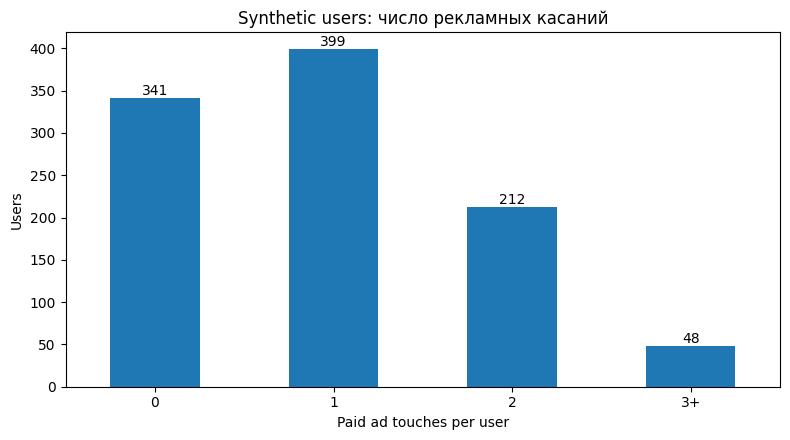

saved: /content/hackaton_project/outputs/charts/synthetic_touch_distribution.png


In [38]:

# Распределение пользователей по числу рекламных касаний.
touch_distribution = (
    population["touch_bucket"]
    .value_counts(sort=False)
    .reindex(["0", "1", "2", "3+"])
)

fig, ax = plt.subplots(figsize=(8, 4.5))
touch_distribution.plot(kind="bar", ax=ax)
ax.set_title("Synthetic users: число рекламных касаний")
ax.set_xlabel("Paid ad touches per user")
ax.set_ylabel("Users")
ax.tick_params(axis="x", rotation=0)

for i, value in enumerate(touch_distribution.values):
    ax.text(i, value, str(int(value)), ha="center", va="bottom")

fig.tight_layout()
TOUCH_DIST_CHART = OUTPUT_DIR / "synthetic_touch_distribution.png"
fig.savefig(TOUCH_DIST_CHART, dpi=160, bbox_inches="tight")
plt.show()
print("saved:", TOUCH_DIST_CHART)


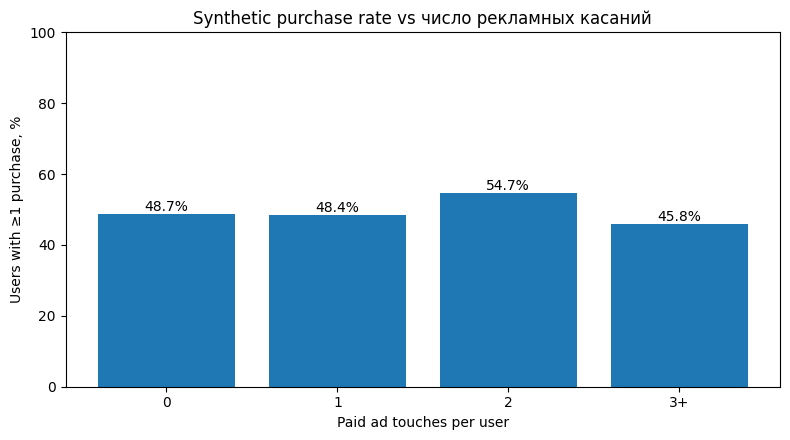

saved: /content/hackaton_project/outputs/charts/synthetic_purchase_rate_by_touches.png


In [39]:

# Purchase rate в зависимости от количества рекламных касаний.
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(conversion_by_touches))
rates = conversion_by_touches["purchase_rate"] * 100

ax.bar(x, rates)
ax.set_xticks(x)
ax.set_xticklabels(conversion_by_touches["touch_bucket"].astype(str))
ax.set_ylim(0, max(100, float(rates.max()) * 1.15))
ax.set_title("Synthetic purchase rate vs число рекламных касаний")
ax.set_xlabel("Paid ad touches per user")
ax.set_ylabel("Users with ≥1 purchase, %")

for i, value in enumerate(rates):
    ax.text(i, value, f"{value:.1f}%", ha="center", va="bottom")

fig.tight_layout()
PURCHASE_RATE_CHART = OUTPUT_DIR / "synthetic_purchase_rate_by_touches.png"
fig.savefig(PURCHASE_RATE_CHART, dpi=160, bbox_inches="tight")
plt.show()
print("saved:", PURCHASE_RATE_CHART)


placement_id,a,b,c,d
placement_id,,,,
a,94,37,23,90
b,0,87,16,65
c,0,0,74,27
d,0,0,0,146


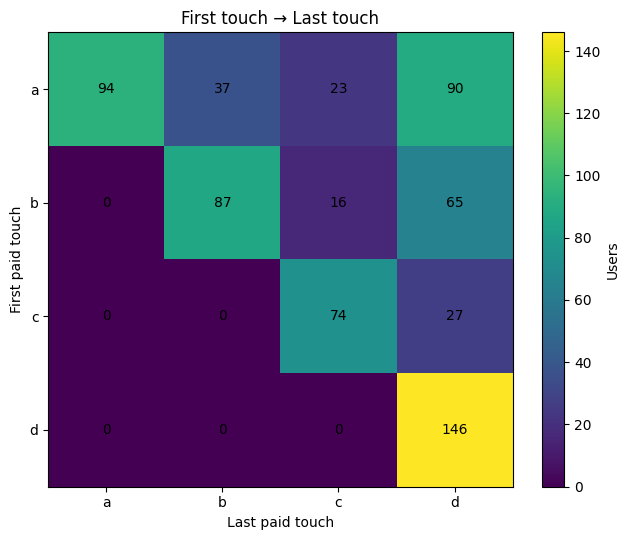

saved: /content/hackaton_project/outputs/charts/synthetic_first_last_matrix.png


In [40]:

# First-touch → Last-touch matrix.
# Показываем только пользователей хотя бы с одним paid touch.
paid_population = population[population["n_ad_touches"] > 0].copy()

first_last = pd.crosstab(
    paid_population["first_touch"],
    paid_population["last_touch"],
).reindex(
    index=placements["placement_id"],
    columns=placements["placement_id"],
    fill_value=0,
)

display(first_last)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(first_last.values, aspect="auto")
ax.set_xticks(np.arange(len(first_last.columns)))
ax.set_xticklabels(first_last.columns)
ax.set_yticks(np.arange(len(first_last.index)))
ax.set_yticklabels(first_last.index)
ax.set_xlabel("Last paid touch")
ax.set_ylabel("First paid touch")
ax.set_title("First touch → Last touch")

for i in range(first_last.shape[0]):
    for j in range(first_last.shape[1]):
        ax.text(j, i, int(first_last.iloc[i, j]), ha="center", va="center")

fig.colorbar(im, ax=ax, label="Users")
fig.tight_layout()
FIRST_LAST_CHART = OUTPUT_DIR / "synthetic_first_last_matrix.png"
fig.savefig(FIRST_LAST_CHART, dpi=160, bbox_inches="tight")
plt.show()
print("saved:", FIRST_LAST_CHART)


,first_touch_share,last_touch_share
placement_id,,
a,37.0%,14.3%
b,25.5%,18.8%
c,15.3%,17.1%
d,22.2%,49.8%


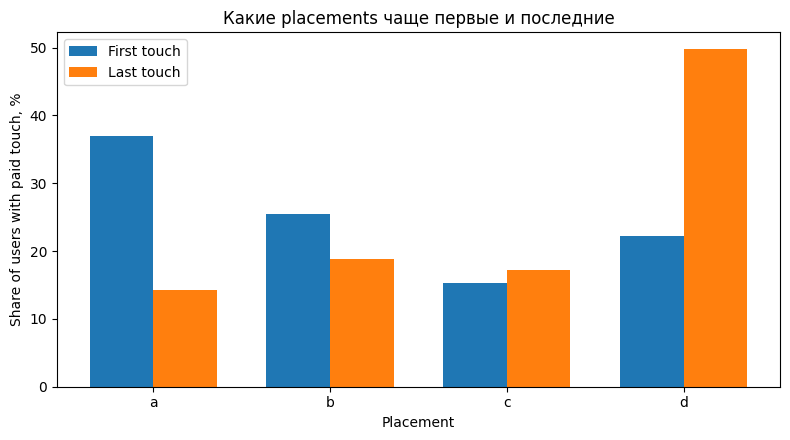

saved: /content/hackaton_project/outputs/charts/synthetic_first_last_share.png


In [41]:

# Отдельно показываем, какие placements чаще являются первым и последним касанием.
first_share = (
    paid_population["first_touch"]
    .value_counts(normalize=True)
    .reindex(placements["placement_id"], fill_value=0)
)
last_share = (
    paid_population["last_touch"]
    .value_counts(normalize=True)
    .reindex(placements["placement_id"], fill_value=0)
)

first_last_share = pd.DataFrame({
    "first_touch_share": first_share,
    "last_touch_share": last_share,
})
display(first_last_share.style.format("{:.1%}"))

fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(first_last_share))
width = 0.36
ax.bar(x - width/2, first_last_share["first_touch_share"] * 100, width, label="First touch")
ax.bar(x + width/2, first_last_share["last_touch_share"] * 100, width, label="Last touch")
ax.set_xticks(x)
ax.set_xticklabels(first_last_share.index)
ax.set_ylabel("Share of users with paid touch, %")
ax.set_xlabel("Placement")
ax.set_title("Какие placements чаще первые и последние")
ax.legend()
fig.tight_layout()

FIRST_LAST_SHARE_CHART = OUTPUT_DIR / "synthetic_first_last_share.png"
fig.savefig(FIRST_LAST_SHARE_CHART, dpi=160, bbox_inches="tight")
plt.show()
print("saved:", FIRST_LAST_SHARE_CHART)



## 4. Attribution engine

В production-режиме ниже вызывается **тот же код, что использует бот**.

В fallback-режиме используется локальная реализация только для того, чтобы ноутбук можно было открыть и выполнить без всего репозитория.


In [42]:
def fallback_compute(touches, orders, model="last", window_days=30):
    """
    Параметры функции:
      touches: факт рекламных или органических касаний пользователей
      orders: совершенные заказы
      model: модель атрибуции ('last', 'first', 'linear', 'position', 'organic_adjusted')
      window_days: окно атрибуции (дней)
    """
    заказы = (
        orders[["order_id", "user_id_hash", "amount", "variable_costs", "timestamp"]]
        .sort_values(["user_id_hash", "timestamp"])
        .copy()
    )
    заказы["timestamp"] = pd.to_datetime(заказы["timestamp"])
    заказы["prev_order_ts"] = заказы.groupby("user_id_hash")["timestamp"].shift()

    платные_касания = touches[touches["placement_id"].notna()][
        ["touch_id", "user_id_hash", "placement_id", "timestamp"]
    ].copy()
    платные_касания["timestamp"] = pd.to_datetime(платные_касания["timestamp"])
    платные_касания = платные_касания.rename(columns={"timestamp": "touch_ts"})

    связки = заказы.merge(платные_касания, on="user_id_hash")
    связки = связки[
        (связки["touch_ts"] <= связки["timestamp"])
        & (связки["touch_ts"] >= связки["timestamp"] - pd.Timedelta(days=window_days))
        & (связки["prev_order_ts"].isna() | (связки["touch_ts"] > связки["prev_order_ts"]))
    ].copy()

    связки = связки.sort_values(["order_id", "touch_ts", "touch_id"])
    число_касаний_в_заказе = связки.groupby("order_id")["order_id"].transform("size")
    порядок_касания = связки.groupby("order_id").cumcount()

    if model == "last":
        веса = (порядок_касания == число_касаний_в_заказе - 1).astype(float)
    elif model == "first":
        веса = (порядок_касания == 0).astype(float)
    elif model == "linear":
        веса = 1 / число_касаний_в_заказе
    elif model == "position":
        крайние = (порядок_касания == 0) | (порядок_касания == число_касаний_в_заказе - 1)
        веса = np.select(
            [число_касаний_в_заказе == 1, число_касаний_в_заказе == 2, крайние],
            [1.0, 0.5, 0.4],
            default=0.2 / (число_касаний_в_заказе - 2).clip(lower=1),
        )
    elif model == "organic_adjusted":
        влияние_сезонности = связки["timestamp"].apply(lambda dt: demand_at(dt))
        разница_дней = (связки["timestamp"] - связки["touch_ts"]).dt.total_seconds() / 86400.0
        вес_затухания = np.exp(-разница_дней / 7.0)
        веса = вес_затухания / (1.0 + влияние_сезонности * 1.5)
    else:
        raise ValueError(model)

    связки = связки.assign(weight=веса)
    связки["weight"] = связки["weight"] / связки.groupby("order_id")["weight"].transform("sum").clip(lower=1.0)
    связки = связки[связки["weight"] > 0].copy()

    органика = заказы[~заказы["order_id"].isin(связки["order_id"])].copy()
    органика["touch_id"] = None
    органика["placement_id"] = None
    органика["weight"] = 1.0

    результат = pd.concat([связки, органика], ignore_index=True)
    результат["attributed_revenue"] = результат["amount"] * результат["weight"]
    результат["attributed_margin"] = (результат["amount"] - результат["variable_costs"]) * результат["weight"]

    return результат[
        ["order_id", "touch_id", "placement_id", "weight", "attributed_revenue", "attributed_margin"]
    ]

def model_romi_from_frames(frames, window_days=WINDOW_DAYS):
    models = ("last", "first", "linear", "position", "organic_adjusted")
    costs = placements.set_index("placement_id")["cost"]
    result = {}
    for model in models:
        att = fallback_compute(
            frames["fact_touch"],
            frames["fact_order"],
            model=model,
            window_days=window_days,
        )
        rev = (
            att.dropna(subset=["placement_id"])
            .groupby("placement_id")["attributed_revenue"]
            .sum()
            .reindex(costs.index, fill_value=0)
        )
        result[model] = (rev - costs) / costs
    return pd.DataFrame(result)

model_comparison = model_romi_from_frames(frames)
display(model_comparison)

,last,first,linear,position,organic_adjusted
placement_id,,,,,
a,11.278764,13.919621,12.577883,12.586407,0.767969
b,8.515636,8.954727,8.736697,8.736091,0.278214
c,5.663125,5.264250,5.571396,5.528313,0.189320
d,7.388834,2.562458,4.903146,4.932146,0.804473



## 5. Ground truth и метрики

**True incremental revenue** placement — сумма чеков тех заказов, которые генератор создал именно благодаря рекламе и для которых этот placement был скрытым `true_driver`.

То есть:

\[
TrueROMI = \frac{IncrementalRevenue - Cost}{Cost}
\]

Это намеренно строже обычного attribution ROMI: органические продажи после рекламного касания **не считаются эффектом рекламы**.

Сравниваем модели по четырём метрикам:

- **Top-1 accuracy** — нашли ли placement с максимальным true ROMI;
- **Spearman rank correlation** — правильно ли ранжировали placements;
- **ROMI MAE** — насколько ошиблись в величине ROMI;
- **Sign accuracy** — правильно ли определили знак ROMI (`>0` / `<0`).


In [43]:

MODELS = ("last", "first", "linear", "position")


def true_romi(order_truth):
    costs = placements.set_index("placement_id")["cost"]

    inc_rev = (
        order_truth.dropna(subset=["true_driver"])
        .groupby("true_driver")["amount"]
        .sum()
        .reindex(costs.index, fill_value=0.0)
    )

    return (inc_rev - costs) / costs


def evaluate_run(frames):
    truth = true_romi(frames["order_truth"])
    predicted = model_romi_from_frames(frames).reindex(truth.index)

    true_best = truth.idxmax()
    true_rank = truth.rank(ascending=False, method="average")

    rows = []
    for model in MODELS:
        p = predicted[model].reindex(truth.index)
        pred_rank = p.rank(ascending=False, method="average")

        rows.append({
            "model": model,
            "top1_correct": int(p.idxmax() == true_best),
            "rank_correlation": true_rank.corr(pred_rank, method="pearson"),
            "romi_mae": float((p - truth).abs().mean()),
            "sign_accuracy": float((np.sign(p) == np.sign(truth)).mean()),
            "mean_bias": float((p - truth).mean()),
        })

    return pd.DataFrame(rows), truth, predicted


one_run_score, truth, predicted = evaluate_run(frames)

comparison = pd.DataFrame({"true_incremental_romi": truth}).join(predicted)
display(comparison.sort_values("true_incremental_romi", ascending=False))
display(one_run_score)


,true_incremental_romi,last,first,linear,position,organic_adjusted
placement_id,,,,,,
a,0.773071,11.278764,13.919621,12.577883,12.586407,0.767969
b,0.038455,8.515636,8.954727,8.736697,8.736091,0.278214
c,-0.577500,5.663125,5.264250,5.571396,5.528313,0.189320
d,-1.000000,7.388834,2.562458,4.903146,4.932146,0.804473


,model,top1_correct,rank_correlation,romi_mae,sign_accuracy,mean_bias
0,last,1,0.8,8.403083,0.5,8.403083
1,first,1,1.0,7.866758,0.5,7.866758
2,linear,1,1.0,8.138774,0.5,8.138774
3,position,1,1.0,8.137233,0.5,8.137233


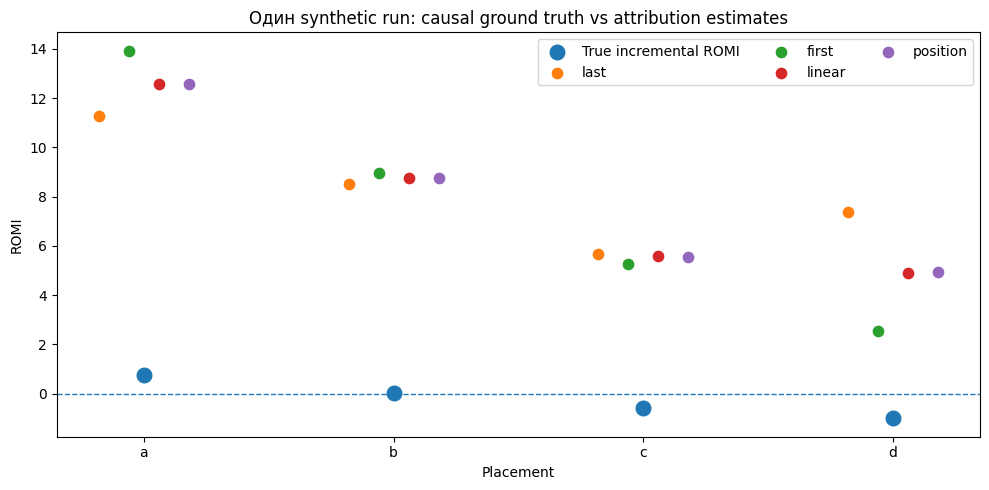

saved: /content/hackaton_project/outputs/charts/synthetic_true_vs_attribution_romi.png


In [44]:

# Визуализация одного запуска: true incremental ROMI vs attribution ROMI.
plot_df = comparison.reset_index().rename(columns={"index": "placement_id"})
long = plot_df.melt(
    id_vars=["placement_id", "true_incremental_romi"],
    value_vars=list(MODELS),
    var_name="model",
    value_name="estimated_romi",
)

# Для читаемости показываем true ROMI отдельно и оценки моделей рядом как точки.
fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(plot_df))
ax.scatter(x, plot_df["true_incremental_romi"], s=110, label="True incremental ROMI")

offsets = np.linspace(-0.18, 0.18, len(MODELS))
for off, model in zip(offsets, MODELS):
    ax.scatter(x + off, plot_df[model], s=55, label=model)

ax.axhline(0, linestyle="--", linewidth=1)
ax.set_xticks(x)
ax.set_xticklabels(plot_df["placement_id"])
ax.set_ylabel("ROMI")
ax.set_xlabel("Placement")
ax.set_title("Один synthetic run: causal ground truth vs attribution estimates")
ax.legend(ncol=3)
fig.tight_layout()

ONE_RUN_CHART = OUTPUT_DIR / "synthetic_true_vs_attribution_romi.png"
fig.savefig(ONE_RUN_CHART, dpi=160, bbox_inches="tight")
plt.show()
print("saved:", ONE_RUN_CHART)


### 📋 Техническое задание (ТЗ): Переход к динамическому учету внешних факторов и категорий рекламы

Чтобы сделать расчет окупаемости рекламы максимально точным и приближенным к реальности, нам нужно связать внешние бизнес-события с математическим ядром атрибуции.

#### 1. Что необходимо начать отслеживать на стороне продакшн-системы (База данных):
1. **Категории и метаданные рекламных публикаций:**
   * Поля в таблице `dim_placement`: `post_category` (`sale_discount` / `expert_content` / `event_announcement` / `regular_post`).
   * Поле `target_product_id` (какой конкретно курс рекламировался, чтобы не размывать эффект на всю линейку).
2. **Метрики вовлечения постов (в первые 48 часов):**
   * Число просмотров (`views_count`) и пересылок постов в Telegram.
   * Это позволит рассчитывать взвешенный охват вместо статического `reach`.
3. **Календарь внутренних и внешних событий (Таблица `dim_events`):**
   * Даты проведения бесплатных вебинаров, интенсивов, стартов потоков и общих праздников.
4. **Исторический тренд органики:**
   * Ежедневный объем регистраций пользователей без активных рекламных сессий за последние 14 дней.

#### 2. Что нужно внедрить в логику синтетического генератора (Имитатор):
1. **Динамический Decay Rate (Период затухания):**
   * Вместо глобальной константы `DECAY_DAYS = 7.0` вычислять индивидуальный период распада клика: для категории `discount` ставить `3.0` дня, для экспертного прогрева `content` — `14.0` дней.
2. **Эндогенный синергетический эффект (Подогрев интереса):**
   * Если реклама категории `event_announcement` выходит за 3 дня до даты вебинара, базовая вероятность органической покупки `p_organic` в день вебинара для этого пользователя должна мультипликативно увеличиваться на $1.5\times$.
3. **Имитация объемов и виральности:**
   * Генерировать случайную величину просмотров поста, которая напрямую масштабирует скрытую силу `true_daily_lift`.

### 🧹 Очистка ноутбука от нерелевантных моделей

В соответствии с выводами, классические эвристические модели (First, Last, Linear, Position Touch) искажают результаты в условиях сильного органического спроса, создавая иллюзию окупаемости неэффективных каналов.

Ниже мы перестраиваем финальную оценку, фокусируясь исключительно на сравнении **True Causal ROMI** с нашей новой моделью **Organic Adjusted**.

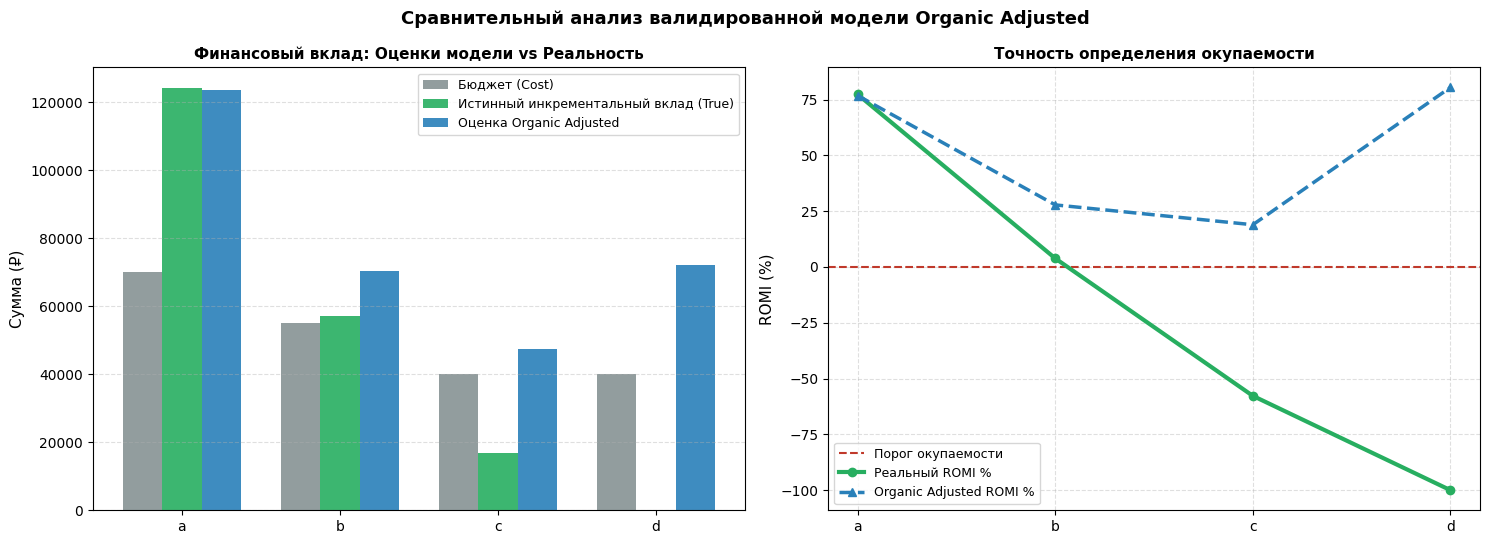

In [45]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Фиксируем только подтвержденные модели
SELECTED_MODELS = ["organic_adjusted"]

стоимость_размещений = placements.set_index("placement_id")["cost"]
реальный_доход = frames["order_truth"].dropna(subset=["true_driver"]).groupby("true_driver")["amount"].sum().reindex(стоимость_размещений.index, fill_value=0.0)

# Расчет показателей для скорректированной модели
доход_organic_adjusted = fallback_compute(
    frames["fact_touch"],
    frames["fact_order"],
    model="organic_adjusted"
).dropna(subset=["placement_id"]).groupby("placement_id")["attributed_revenue"].sum().reindex(стоимость_размещений.index, fill_value=0.0)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
x = np.arange(len(стоимость_размещений))
width = 0.25

# График доходов
axes[0].bar(x - width, стоимость_размещений, width, label='Бюджет (Cost)', color='#7F8C8D', alpha=0.85)
axes[0].bar(x, реальный_доход, width, label='Истинный инкрементальный вклад (True)', color='#27AE60', alpha=0.9)
axes[0].bar(x + width, доход_organic_adjusted, width, label='Оценка Organic Adjusted', color='#2980B9', alpha=0.9)

axes[0].set_ylabel('Сумма (₽)', fontsize=11)
axes[0].set_title('Финансовый вклад: Оценки модели vs Реальность', fontsize=11, weight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(стоимость_размещений.index)
axes[0].legend(fontsize=9)
axes[0].grid(axis='y', linestyle='--', alpha=0.4)

# График ROMI
реальный_romi = (реальный_доход - стоимость_размещений) / стоимость_размещений * 100
romi_organic_adjusted = (доход_organic_adjusted - стоимость_размещений) / стоимость_размещений * 100

axes[1].axhline(0, color='#C0392B', linestyle='--', linewidth=1.5, label='Порог окупаемости')
axes[1].plot(стоимость_размещений.index, реальный_romi, marker='o', color='#27AE60', linewidth=3, label='Реальный ROMI %')
axes[1].plot(стоимость_размещений.index, romi_organic_adjusted, marker='^', color='#2980B9', linewidth=2.5, linestyle='--', label='Organic Adjusted ROMI %')

axes[1].set_ylabel('ROMI (%)', fontsize=11)
axes[1].set_title('Точность определения окупаемости', fontsize=11, weight='bold')
axes[1].legend(fontsize=9)
axes[1].grid(True, linestyle='--', alpha=0.4)

plt.suptitle('Сравнительный анализ валидированной модели Organic Adjusted', fontsize=13, weight='bold')
plt.tight_layout()
plt.show()

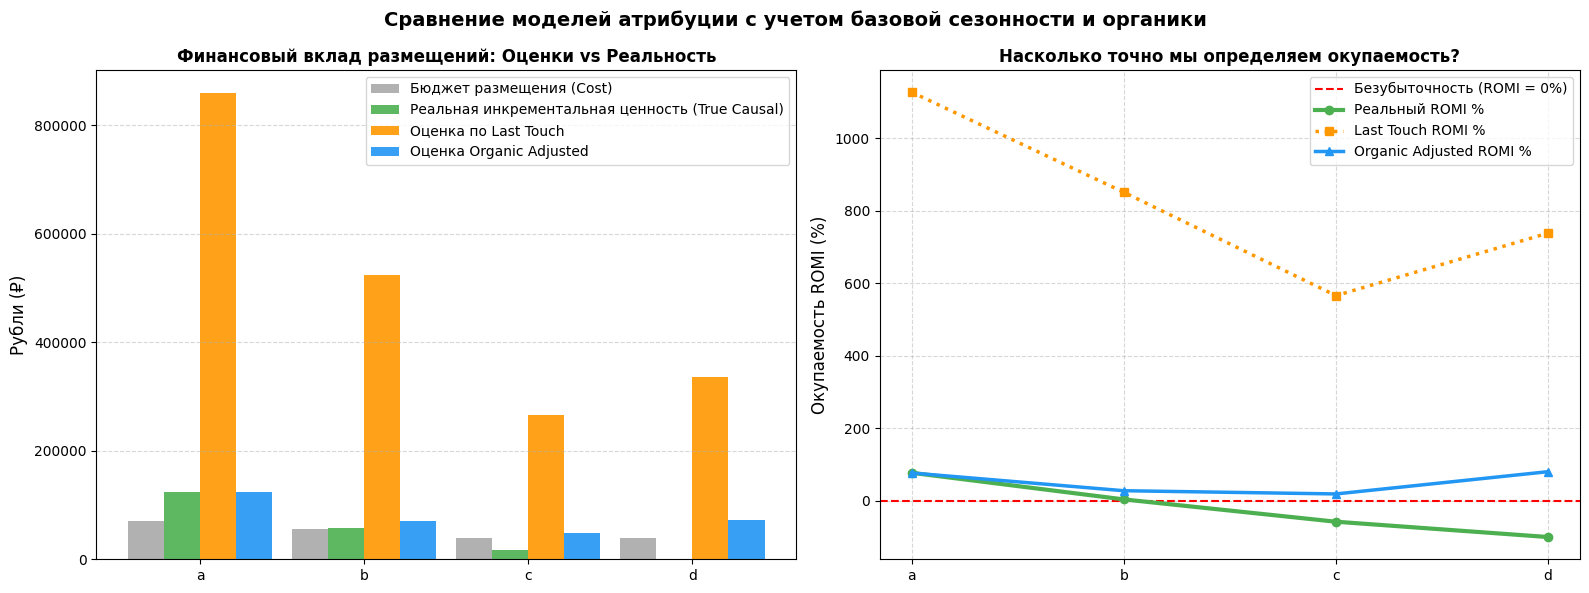

In [46]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

стоимость_размещений = placements.set_index("placement_id")["cost"]
реальный_доход = frames["order_truth"].dropna(subset=["true_driver"]).groupby("true_driver")["amount"].sum().reindex(стоимость_размещений.index, fill_value=0.0)

доход_last_touch = fallback_compute(frames["fact_touch"], frames["fact_order"], model="last")\
    .dropna(subset=["placement_id"]).groupby("placement_id")["attributed_revenue"].sum().reindex(стоимость_размещений.index, fill_value=0.0)

доход_organic_adjusted = fallback_compute(frames["fact_touch"], frames["fact_order"], model="organic_adjusted")\
    .dropna(subset=["placement_id"]).groupby("placement_id")["attributed_revenue"].sum().reindex(стоимость_размещений.index, fill_value=0.0)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
x = np.arange(len(стоимость_размещений))
width = 0.22

axes[0].bar(x - 1.5*width, стоимость_размещений, width, label='Бюджет размещения (Cost)', color='#9E9E9E', alpha=0.8)
axes[0].bar(x - 0.5*width, реальный_доход, width, label='Реальная инкрементальная ценность (True Causal)', color='#4CAF50', alpha=0.9)
axes[0].bar(x + 0.5*width, доход_last_touch, width, label='Оценка по Last Touch', color='#FF9800', alpha=0.9)
axes[0].bar(x + 1.5*width, доход_organic_adjusted, width, label='Оценка Organic Adjusted', color='#2196F3', alpha=0.9)

axes[0].set_ylabel('Рубли (₽)', fontsize=12)
axes[0].set_title('Финансовый вклад размещений: Оценки vs Реальность', fontsize=12, weight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(стоимость_размещений.index)
axes[0].legend(fontsize=10)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

реальный_romi = (реальный_доход - стоимость_размещений) / стоимость_размещений * 100
romi_last_touch = (доход_last_touch - стоимость_размещений) / стоимость_размещений * 100
romi_organic_adjusted = (доход_organic_adjusted - стоимость_размещений) / стоимость_размещений * 100

axes[1].axhline(0, color='red', linestyle='--', linewidth=1.5, label='Безубыточность (ROMI = 0%)')
axes[1].plot(стоимость_размещений.index, реальный_romi, marker='o', color='#4CAF50', linewidth=3, label='Реальный ROMI %')
axes[1].plot(стоимость_размещений.index, romi_last_touch, marker='s', color='#FF9800', linewidth=2.5, linestyle=':', label='Last Touch ROMI %')
axes[1].plot(стоимость_размещений.index, romi_organic_adjusted, marker='^', color='#2196F3', linewidth=2.5, label='Organic Adjusted ROMI %')

axes[1].set_ylabel('Окупаемость ROMI (%)', fontsize=12)
axes[1].set_title('Насколько точно мы определяем окупаемость?', fontsize=12, weight='bold')
axes[1].legend(fontsize=10)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Сравнение моделей атрибуции с учетом базовой сезонности и органики', fontsize=14, weight='bold')
plt.tight_layout()
plt.show()


## 6. Monte Carlo: повторяем эксперимент много раз

Один seed может быть случайно удачным или неудачным. Поэтому итог сравниваем по множеству независимых генераций.

Для хакатонного MVP достаточно `30` прогонов; при необходимости можно увеличить `N_RUNS`.


In [47]:

def run_many(n_runs=N_RUNS, n_users=N_USERS, first_seed=1000):
    rows = []

    for seed in range(first_seed, first_seed + n_runs):
        run_frames = generate_synthetic(seed=seed, n_users=n_users)
        score, _, _ = evaluate_run(run_frames)
        score["seed"] = seed
        rows.append(score)

    return pd.concat(rows, ignore_index=True)


runs = run_many()

summary = (
    runs.groupby("model")
    .agg(
        top1_accuracy=("top1_correct", "mean"),
        mean_rank_correlation=("rank_correlation", "mean"),
        mean_romi_mae=("romi_mae", "mean"),
        sign_accuracy=("sign_accuracy", "mean"),
        mean_bias=("mean_bias", "mean"),
    )
    .sort_values(
        ["mean_rank_correlation", "top1_accuracy"],
        ascending=False,
    )
)

display(summary.style.format({
    "top1_accuracy": "{:.1%}",
    "mean_rank_correlation": "{:.3f}",
    "mean_romi_mae": "{:.3f}",
    "sign_accuracy": "{:.1%}",
    "mean_bias": "{:.3f}",
}))


,top1_accuracy,mean_rank_correlation,mean_romi_mae,sign_accuracy,mean_bias
model,,,,,
first,36.7%,0.507,7.885,34.2%,7.885
linear,40.0%,0.480,8.162,34.2%,8.162
position,40.0%,0.460,8.160,34.2%,8.160
last,43.3%,0.393,8.430,34.2%,8.430


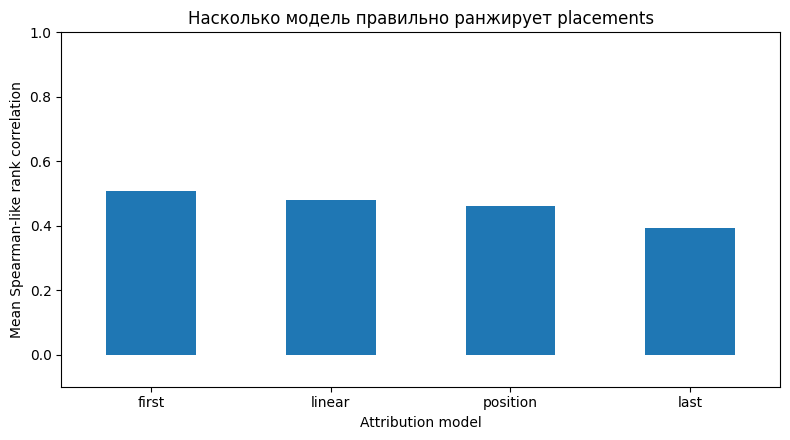

saved: /content/hackaton_project/outputs/charts/synthetic_model_rank_correlation.png


In [48]:

# Итоговая визуализация: rank correlation.
fig, ax = plt.subplots(figsize=(8, 4.5))
rank_plot = summary["mean_rank_correlation"].sort_values(ascending=False)
rank_plot.plot(kind="bar", ax=ax)
ax.set_ylim(min(-0.1, rank_plot.min() - 0.05), 1.0)
ax.set_ylabel("Mean Spearman-like rank correlation")
ax.set_xlabel("Attribution model")
ax.set_title("Насколько модель правильно ранжирует placements")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()

RANK_CHART = OUTPUT_DIR / "synthetic_model_rank_correlation.png"
fig.savefig(RANK_CHART, dpi=160, bbox_inches="tight")
plt.show()
print("saved:", RANK_CHART)


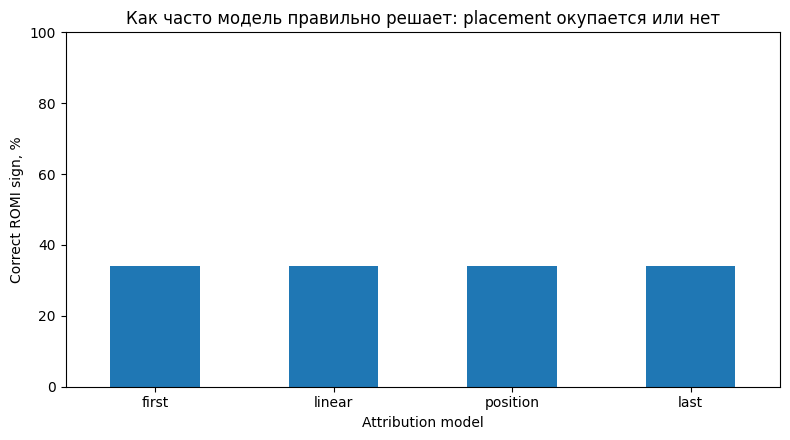

saved: /content/hackaton_project/outputs/charts/synthetic_model_sign_accuracy.png


In [49]:

# Итоговая визуализация: sign accuracy.
fig, ax = plt.subplots(figsize=(8, 4.5))
sign_plot = (summary["sign_accuracy"] * 100).sort_values(ascending=False)
sign_plot.plot(kind="bar", ax=ax)
ax.set_ylim(0, 100)
ax.set_ylabel("Correct ROMI sign, %")
ax.set_xlabel("Attribution model")
ax.set_title("Как часто модель правильно решает: placement окупается или нет")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()

SIGN_CHART = OUTPUT_DIR / "synthetic_model_sign_accuracy.png"
fig.savefig(SIGN_CHART, dpi=160, bbox_inches="tight")
plt.show()
print("saved:", SIGN_CHART)



## 7. Как интерпретировать результат

Главный вывод этого эксперимента **не должен быть заранее задан**.

Правильная логика после запуска:

1. Смотрим на `mean_rank_correlation`: какая модель стабильнее ранжирует placements.
2. Проверяем `top1_accuracy`: как часто выбран лучший placement.
3. Проверяем `sign_accuracy`: насколько надёжно решение “масштабировать / не масштабировать”.
4. Смотрим на `mean_bias` и `ROMI MAE`:
   - положительный bias означает, что attribution систематически переоценивает causal ROMI;
   - это ожидаемо, если реклама размещается рядом с сезонными пиками.

### Почему это полезно для кейса

Даже если одна attribution-модель показывает лучшие synthetic-метрики, это **не превращает её в causal estimator**.

Synthetic stress-test показывает:
- как rule-based модели ведут себя при известной скрытой правде;
- насколько вывод чувствителен к модели;
- какие placements можно считать устойчивыми кандидатами на масштабирование.

Для реального incremental ROMI следующий уровень — holdout / randomized promotion / другой causal design.
